In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Contingency table: Campaign response by customer type

data = {
    "Customer_Type": ["New", "New", "Existing", "Existing"],
    "Responded": ["Yes", "No", "Yes", "No"],
    "Count": [30, 20, 40, 10]
}

contingency = pd.DataFrame(data)

contingency

,Customer_Type,Responded,Count
0,New,Yes,30
1,New,No,20
2,Existing,Yes,40
3,Existing,No,10


In [3]:
# Total number of customers
total = contingency["Count"].sum()

# P(A): Probability that a customer responded
p_responded = contingency.loc[
    contingency["Responded"] == "Yes", "Count"
].sum() / total

# P(A ∩ B): Probability that a customer is Existing AND Responded
p_existing_and_responded = contingency.loc[
    (contingency["Customer_Type"] == "Existing") &
    (contingency["Responded"] == "Yes"), "Count"
].sum() / total

# P(A | B): Probability of responding given that the customer is Existing
existing_total = contingency.loc[
    contingency["Customer_Type"] == "Existing", "Count"
].sum()

existing_responded = contingency.loc[
    (contingency["Customer_Type"] == "Existing") &
    (contingency["Responded"] == "Yes"), "Count"
].sum()

p_responded_given_existing = existing_responded / existing_total

print("P(Responded) =", p_responded)
print("P(Existing AND Responded) =", p_existing_and_responded)
print("P(Responded | Existing) =", p_responded_given_existing)

P(Responded) = 0.7
P(Existing AND Responded) = 0.4
P(Responded | Existing) = 0.8


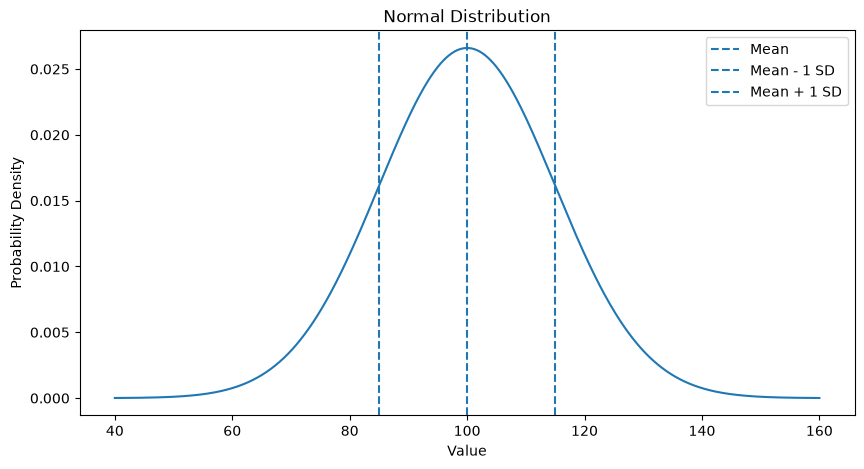

In [4]:
# Generate normal distribution data
mean = 100
std_dev = 15

x = np.linspace(mean - 4*std_dev, mean + 4*std_dev, 1000)

y = (1 / (std_dev * np.sqrt(2 * np.pi))) * \
    np.exp(-0.5 * ((x - mean) / std_dev) ** 2)

plt.figure(figsize=(10, 5))
plt.plot(x, y)

plt.axvline(mean, linestyle="--", label="Mean")
plt.axvline(mean - std_dev, linestyle="--", label="Mean - 1 SD")
plt.axvline(mean + std_dev, linestyle="--", label="Mean + 1 SD")

plt.title("Normal Distribution")
plt.xlabel("Value")
plt.ylabel("Probability Density")
plt.legend()

plt.show()

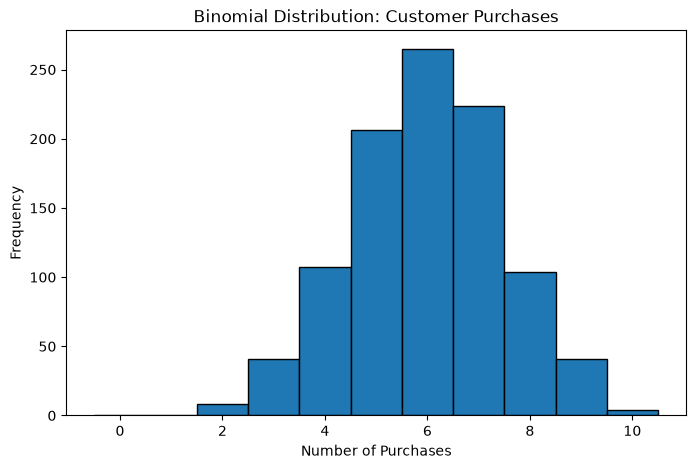

In [5]:
# Binomial distribution simulation

n = 10          # Number of trials
p = 0.6         # Probability of success
simulations = 1000

results = np.random.binomial(n, p, simulations)

plt.figure(figsize=(8, 5))

plt.hist(
    results,
    bins=np.arange(-0.5, n + 1.5, 1),
    edgecolor="black"
)

plt.title("Binomial Distribution: Customer Purchases")
plt.xlabel("Number of Purchases")
plt.ylabel("Frequency")

plt.show()

In [6]:
print("Average number of purchases:", results.mean())
print("Minimum purchases:", results.min())
print("Maximum purchases:", results.max())

Average number of purchases: 5.996
Minimum purchases: 2
Maximum purchases: 10


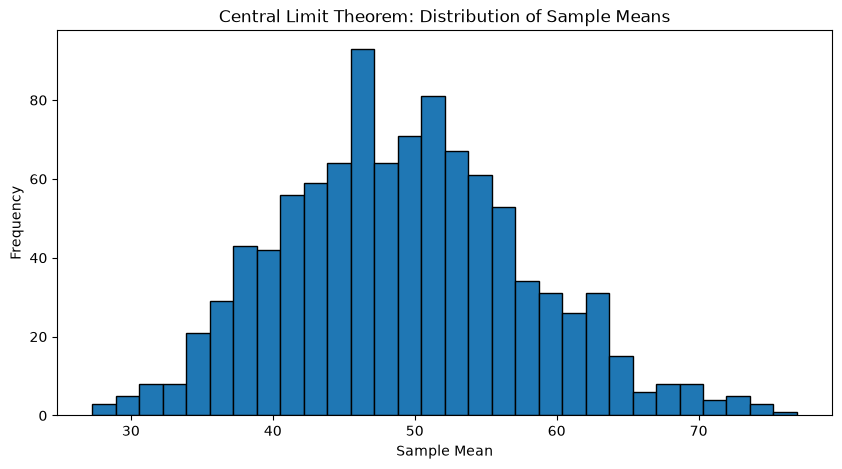

Population Mean: 48.874947734511736
Mean of Sample Means: 49.192293525965276


In [7]:
# Central Limit Theorem simulation

np.random.seed(42)

# Create a non-normal population
population = np.random.exponential(scale=50, size=10000)

# Take many samples and calculate their means
sample_means = []

for i in range(1000):
    sample = np.random.choice(population, size=30)
    sample_means.append(sample.mean())

# Plot distribution of sample means
plt.figure(figsize=(10, 5))

plt.hist(sample_means, bins=30, edgecolor="black")

plt.title("Central Limit Theorem: Distribution of Sample Means")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")

plt.show()

print("Population Mean:", population.mean())
print("Mean of Sample Means:", np.mean(sample_means))

In [8]:
print("WEEK 4 - DAY 2: PROBABILITY SUMMARY")
print("===================================")

print("\nBasic Probabilities:")
print("P(Responded) =", p_responded)
print("P(Existing AND Responded) =", p_existing_and_responded)
print("P(Responded | Existing) =", p_responded_given_existing)

print("\nBinomial Distribution:")
print("Average purchases =", results.mean())

print("\nCentral Limit Theorem:")
print("Population mean =", population.mean())
print("Mean of sample means =", np.mean(sample_means))

WEEK 4 - DAY 2: PROBABILITY SUMMARY

Basic Probabilities:
P(Responded) = 0.7
P(Existing AND Responded) = 0.4
P(Responded | Existing) = 0.8

Binomial Distribution:
Average purchases = 5.996

Central Limit Theorem:
Population mean = 48.874947734511736
Mean of sample means = 49.192293525965276
